## Brain Tumor Segmentation with YOLOv11

This notebook reproduces the method proposed by [Priyadharshini et. al.](https://doi.org/10.1038/s41598-025-13155-4).

Their methodology has been as follow –

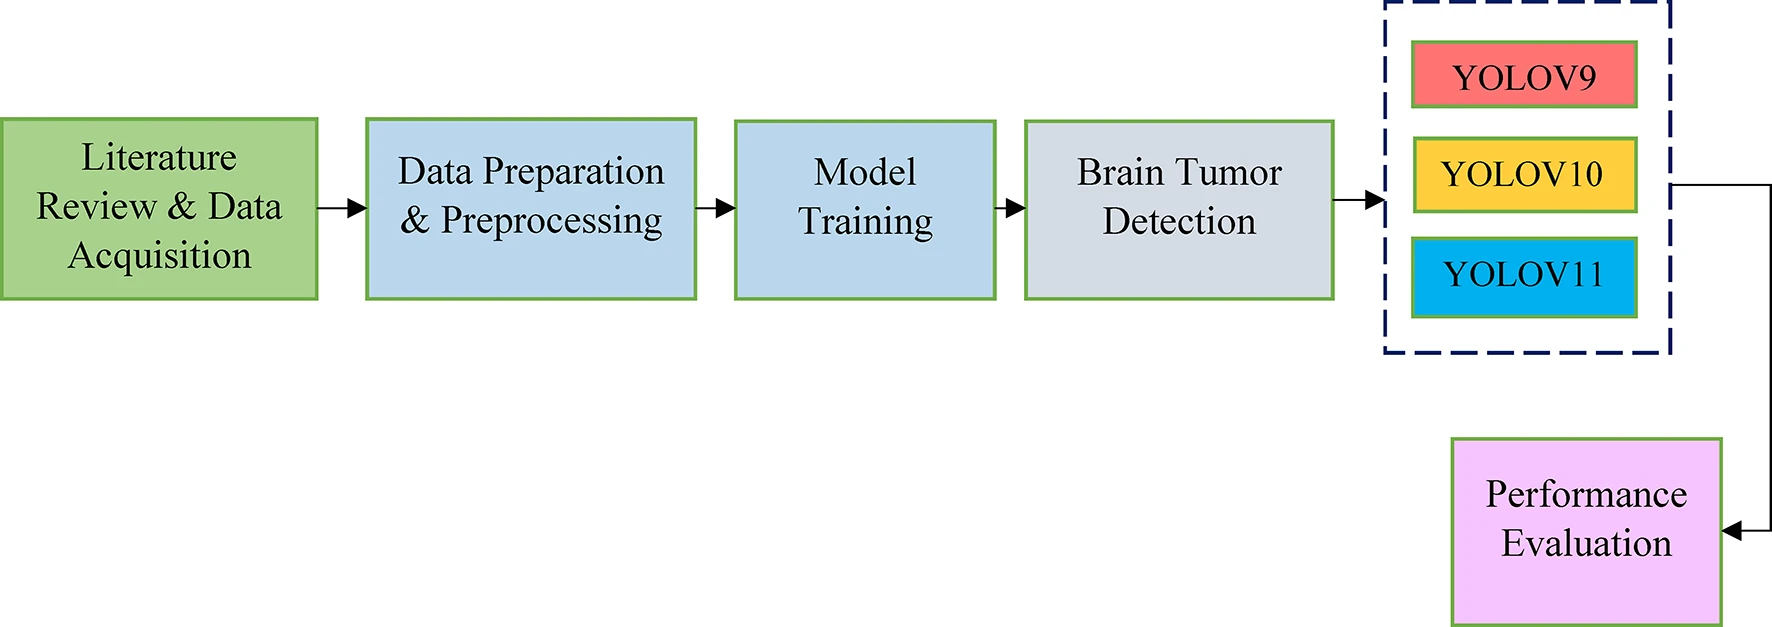

The model works as follows end-to-end.

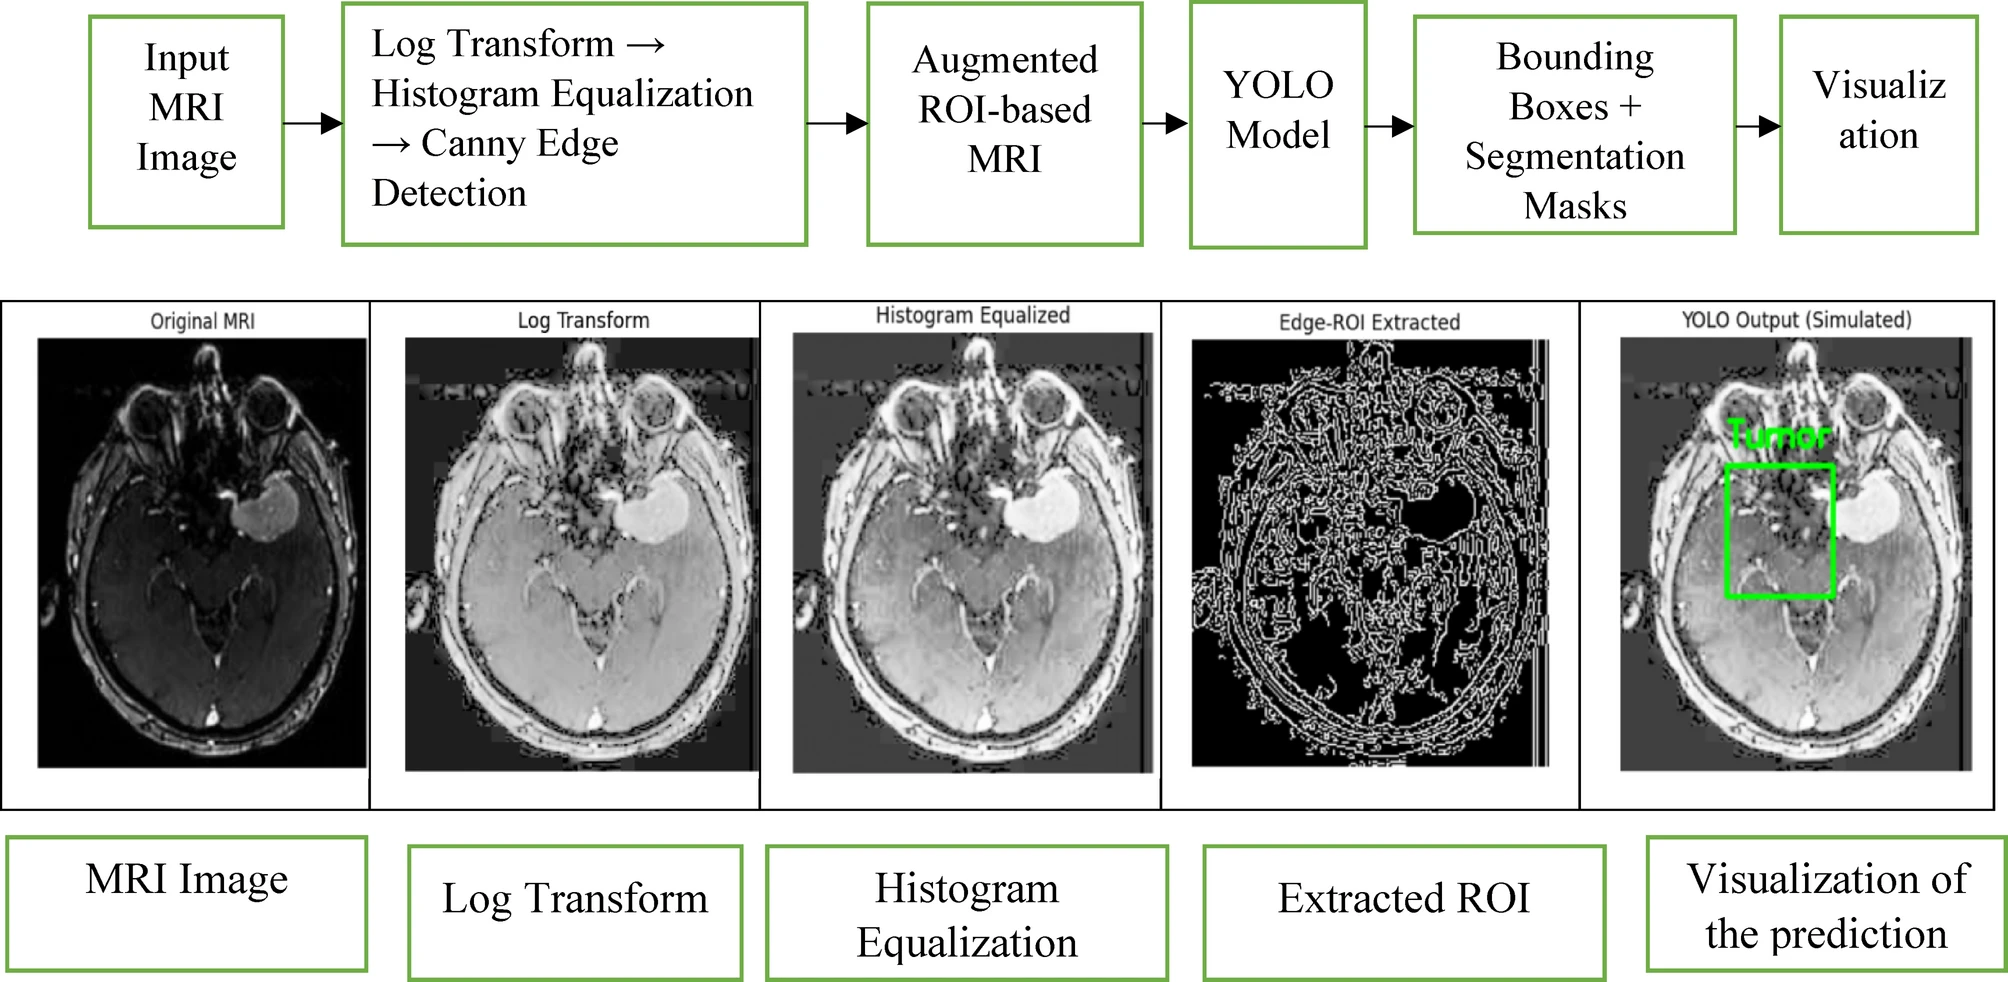

### Data Collection

The data on which the model is trained is `BraTS 2020` provided by *Awsaf* on `kaggle.com`

The description of dataset is as follows –

<h2>About Dataset</h2>

<h3>Overview</h3>

BraTS has always been focusing on the evaluation of state-of-the-art methods for the segmentation of brain tumors in multimodal magnetic resonance imaging (MRI) scans. BraTS 2020 utilizes multi-institutional pre-operative MRI scans and primarily focuses on the segmentation (Task 1) of intrinsically heterogeneous (in appearance, shape, and histology) brain tumors, namely gliomas. Furthemore, to pinpoint the clinical relevance of this segmentation task, BraTS’20 also focuses on the prediction of patient overall survival (Task 2), and the distinction between pseudoprogression and true tumor recurrence (Task 3), via integrative analyses of radiomic features and machine learning algorithms. Finally, BraTS'20 intends to evaluate the algorithmic uncertainty in tumor segmentation (Task 4).

<h3>Tasks' Description and Evaluation Framework</h3>

In this year's challenge, 4 reference standards are used for the 4 tasks of the challenge:

    Manual segmentation labels of tumor sub-regions,
    Clinical data of overall survival,
    Clinical evaluation of progression status,
    Uncertainty estimation for the predicted tumor sub-regions.

<h3>Imaging Data Description</h3>

All BraTS multimodal scans are available as NIfTI files (.nii.gz) and describe a) native (T1) and b) post-contrast T1-weighted (T1Gd), c) T2-weighted (T2), and d) T2 Fluid Attenuated Inversion Recovery (T2-FLAIR) volumes, and were acquired with different clinical protocols and various scanners from multiple (n=19) institutions, mentioned as data contributors here.

All the imaging datasets have been segmented manually, by one to four raters, following the same annotation protocol, and their annotations were approved by experienced neuro-radiologists. Annotations comprise the GD-enhancing tumor (ET — label 4), the peritumoral edema (ED — label 2), and the necrotic and non-enhancing tumor core (NCR/NET — label 1), as described both in the BraTS 2012-2013 TMI paper and in the latest BraTS summarizing paper. The provided data are distributed after their pre-processing, i.e., co-registered to the same anatomical template, interpolated to the same resolution (1 mm^3) and skull-stripped.
Use of Data Beyond BraTS

Participants are allowed to use additional public and/or private data (from their own institutions) for data augmentation, only if they also report results using only the BraTS'20 data and discuss any potential difference in their papers and results. This is due to our intentions to provide a fair comparison among the participating methods.

In [1]:
import os
import gc
import shutil
import subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import cv2
import yaml
from PIL import Image, ImageOps

import torch
import torchvision.transforms as T

In [2]:

import shutil
import subprocess
from pathlib import Path

import yaml
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/brats")
ARCHIVE = DRIVE_DIR / "brats-yolo-v2.tar"
DRIVE_RUNS = DRIVE_DIR / "runs"
LOCAL_DATA = Path("/content/brats-yolo-v2")
LOCAL_TAR = Path("/content/_brats.tar")

DRIVE_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_RUNS.mkdir(parents=True, exist_ok=True)


def fix_yaml():
  """data.yaml holds an absolute path; rewrite it for this session."""
  path = LOCAL_DATA / "data.yaml"
  config = yaml.safe_load(path.read_text())
  config["path"] = str(LOCAL_DATA)
  path.write_text(yaml.safe_dump(config, sort_keys=False))


def restore():
  """Drive -> local disk. False if nothing is archived yet.

  One tar rather than 7k loose files: Drive's FUSE mount has high per-file
  latency, so copying files individually takes minutes where a single
  sequential read takes seconds.
  """
  if LOCAL_DATA.exists() and (LOCAL_DATA / "data.yaml").exists():
    print(f"already on local disk: {LOCAL_DATA}")
    return True

  if not ARCHIVE.exists():
    return False

  print(f"restoring from {ARCHIVE} ...")
  shutil.copy(ARCHIVE, LOCAL_TAR)
  LOCAL_DATA.mkdir(parents=True, exist_ok=True)
  subprocess.run(["tar", "-xf", str(LOCAL_TAR), "-C", str(LOCAL_DATA)], check=True)
  LOCAL_TAR.unlink()
  fix_yaml()

  n = len(list((LOCAL_DATA / "images" / "train").glob("*.png")))
  print(f"restored, {n} training images")
  return True


def archive():
  """local disk -> Drive."""
  subprocess.run(["tar", "-cf", str(LOCAL_TAR), "-C", str(LOCAL_DATA), "."], check=True)
  shutil.copy(LOCAL_TAR, ARCHIVE)
  LOCAL_TAR.unlink()
  print(f"archived to {ARCHIVE} ({ARCHIVE.stat().st_size / 1e6:.0f} MB)")


DATA_READY = restore()

if DATA_READY:
  RAW = None
  print("\nprocessed dataset restored -- skip the preprocessing cell")
else:
  import kagglehub
  RAW = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
  print(f"\nraw dataset at {RAW}")
  print("nothing archived yet -- run the preprocessing cell below")

print(f"data -> {LOCAL_DATA}")
print(f"runs -> {DRIVE_RUNS}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

raw dataset at /kaggle/input/brats20-dataset-training-validation
nothing archived yet -- run the preprocessing cell below
data -> /content/brats-yolo-v2
runs -> /content/drive/MyDrive/brats/runs


In [3]:
import os

# Create a symbolic link in /content to make the dataset visible in the Files tab
symlink_path = '/content/brain-tumor-mri-dataset'
if not os.path.exists(symlink_path):
    # Using RAW as the target path since it holds the downloaded dataset path
    os.symlink(RAW, symlink_path)
    print(f"Symbolic link created! You can now access and view the files in the left panel at: {symlink_path}")
else:
    print("Link already exists.")

Link already exists.


BraTS2020_TrainingData: 369 cases
BraTS2020_ValidationData: 125 cases


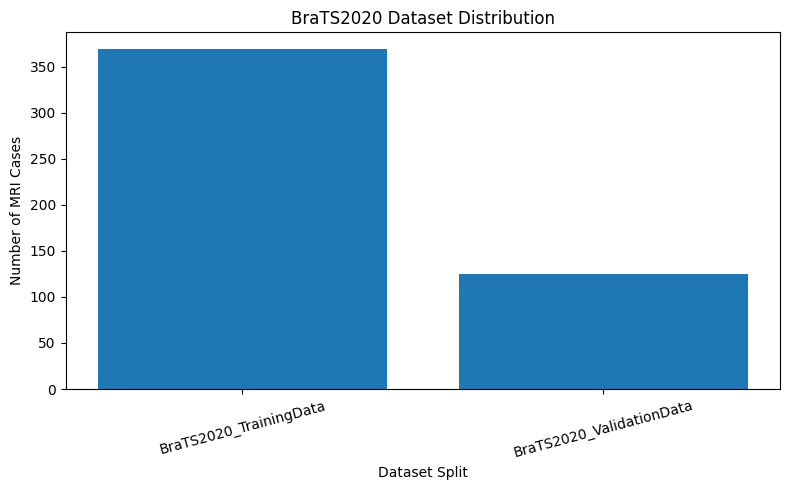

In [4]:
root = Path("/content/brain-tumor-mri-dataset")

splits = [
    "BraTS2020_TrainingData",
    "BraTS2020_ValidationData"
]

counts = {}

for split in splits:
    split_dir = root / split

    # Find the directory containing the individual case folders
    case_dirs = list(split_dir.rglob("BraTS20_*"))

    counts[split] = len([
        p for p in case_dirs
        if p.is_dir() and any(p.glob("*_flair.nii"))
    ])

    print(f"{split}: {counts[split]} cases")

# Plot distribution
plt.figure(figsize=(8, 5))
plt.bar(counts.keys(), counts.values())
plt.title("BraTS2020 Dataset Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of MRI Cases")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

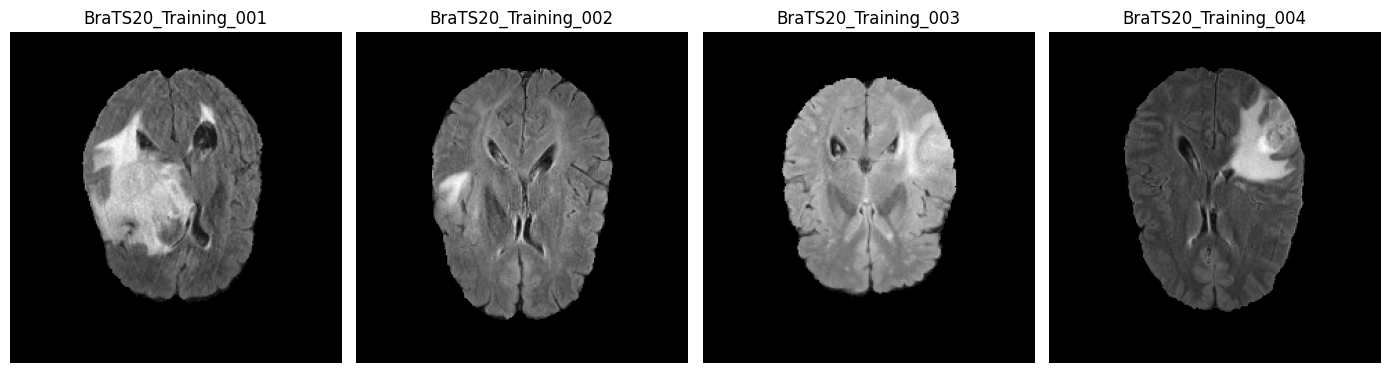

In [5]:
# displaying example scans
root = Path("/content/brain-tumor-mri-dataset/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData")

cases = sorted(root.glob("BraTS20_Training_*"))[:4]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, case in zip(axes, cases):
    img_path = next(case.glob("*_flair.nii"))
    volume = nib.load(img_path).get_fdata()

    # Display the middle axial slice
    slice_idx = volume.shape[2] // 2
    img = volume[:, :, slice_idx]

    ax.imshow(img.T, cmap="gray", origin="lower")
    ax.set_title(case.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Data Preparation and Preprocessing

In [6]:
transform = T.Compose([
    T.Resize((512, 512)),
    T.Lambda(lambda img: ImageOps.equalize(img.convert("L"))),
    T.ToTensor(),
    T.Lambda(lambda img: torch.log1p(img) / np.log(2.0))
])

#### Histogram Equalization and Log Transformation

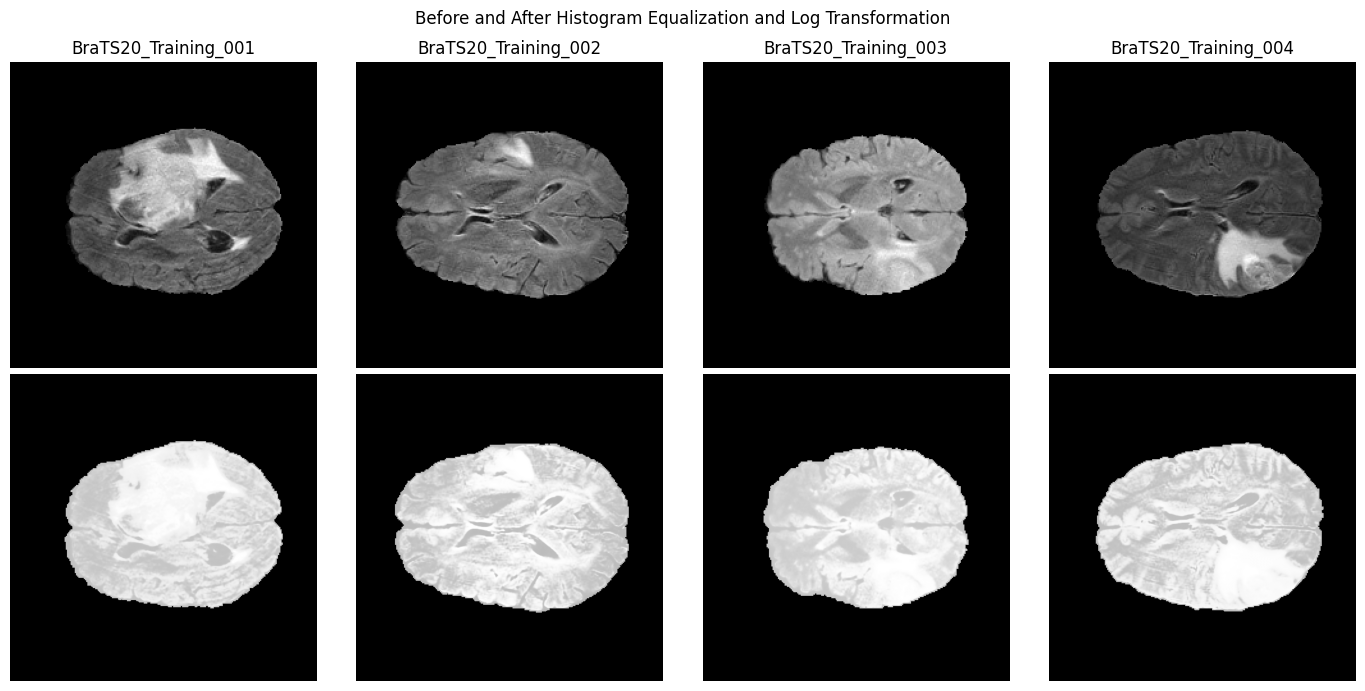

In [7]:
root = Path(
    "/content/brain-tumor-mri-dataset/"
    "BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
)

cases = sorted(root.glob("BraTS20_Training_*"))[:4]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for j, case in enumerate(cases):
    img_path = next(case.glob("*_flair.nii"))
    volume = nib.load(str(img_path)).get_fdata()

    # Extract the middle axial slice
    original = volume[:, :, volume.shape[2] // 2]
    original = np.nan_to_num(original)

    # Scale to 8-bit for PIL-based transforms
    original = (
        (original - original.min()) /
        (original.max() - original.min() + 1e-8) * 255
    ).astype(np.uint8)

    original_pil = Image.fromarray(original)
    processed = transform(original_pil)

    # Original MRI slice
    axes[0, j].imshow(original, cmap="gray")
    axes[0, j].set_title(case.name)
    axes[0, j].axis("off")

    # Transformed MRI slice
    axes[1, j].imshow(
        processed.squeeze(0).numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, j].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=14)
axes[1, 0].set_ylabel("Transformed", fontsize=14)

plt.suptitle(
    "Before and After Histogram Equalization and Log Transformation"
)
plt.tight_layout()
plt.show()

#### Checking for masking

In [8]:
root = Path("/content/brain-tumor-mri-dataset")

# Find training cases
training_root = (
    root / "BraTS2020_TrainingData" /
    "MICCAI_BraTS2020_TrainingData"
)

cases = sorted(training_root.glob("BraTS20_Training_*"))

print("Number of training cases:", len(cases))

# Check for segmentation masks
with_masks = []
without_masks = []

for case in cases:
    masks = list(case.glob("*_seg.nii")) + list(case.glob("*_seg.nii.gz"))

    if masks:
        with_masks.append(case.name)
    else:
        without_masks.append(case.name)

print("Cases with masks:", len(with_masks))
print("Cases without masks:", len(without_masks))

# Inspect file extensions
files = [p for p in root.rglob("*") if p.is_file()]
print("\nFile extensions:", Counter(p.suffix.lower() for p in files))

Number of training cases: 369
Cases with masks: 368
Cases without masks: 1

File extensions: Counter({'.nii': 2345, '.csv': 4})


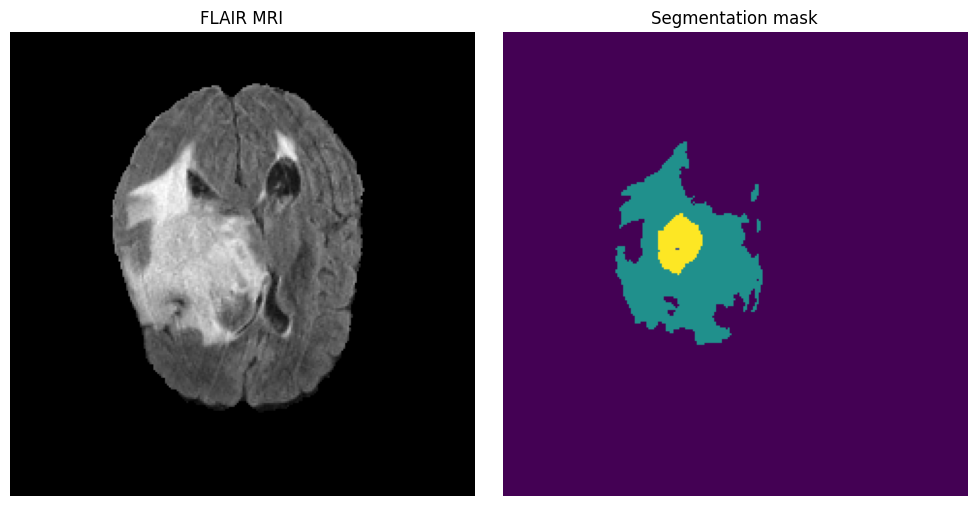

In [9]:
case = cases[0]

flair = nib.load(str(next(case.glob("*_flair.nii")))).get_fdata()
mask = nib.load(str(next(case.glob("*_seg.nii")))).get_fdata()

z = flair.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(flair[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("FLAIR MRI")

axes[1].imshow(mask[:, :, z].T, cmap="viridis", origin="lower")
axes[1].set_title("Segmentation mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Morphological dilation

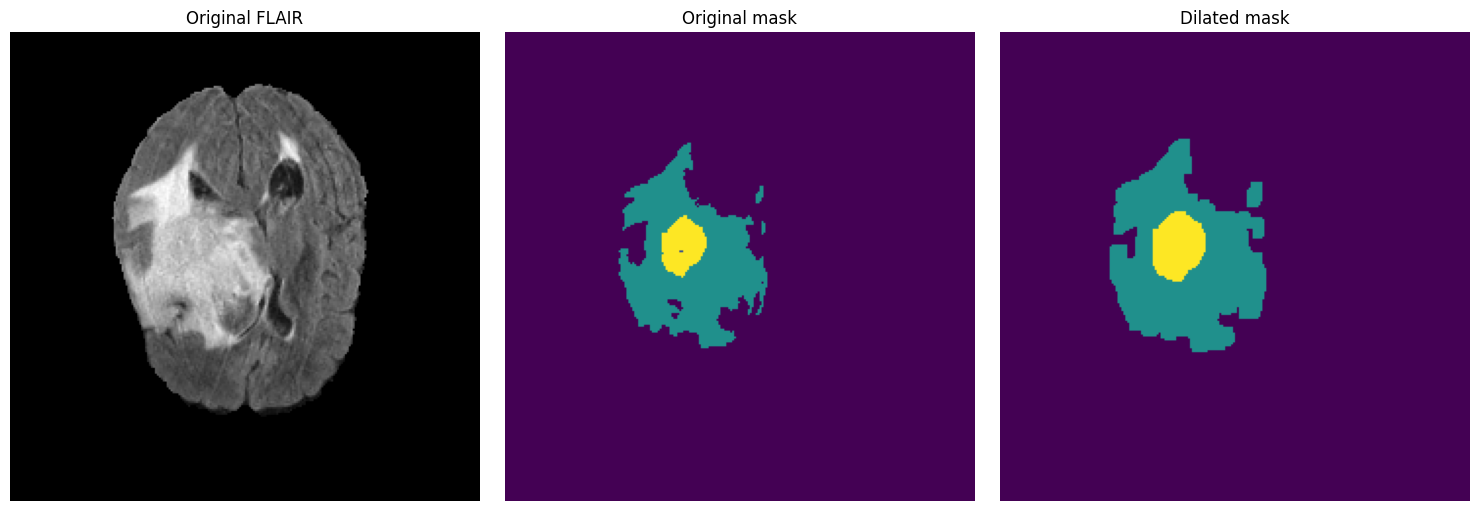

In [10]:
mask_slice = mask[:,:,z].astype(np.uint8)

# morphological dilation
kernel = np.ones((3,3), dtype=np.uint8)
dilated_mask = np.zeros_like(mask_slice)

for label in [1,2,4]:
  region = (mask_slice == label).astype(np.uint8)
  dilated_region = cv2.dilate(region, kernel, iterations=2)
  dilated_mask[dilated_region == 1] = label

# Visualise before and after
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(flair[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("Original FLAIR")

axes[1].imshow(mask_slice.T, cmap="viridis", origin="lower", vmin=0, vmax=4)
axes[1].set_title("Original mask")

axes[2].imshow(dilated_mask.T, cmap="viridis", origin="lower", vmin=0, vmax=4)
axes[2].set_title("Dilated mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Final preprocessing

In [11]:
import gc

class Preprocess:
  MODALITIES = ("flair", "t1", "t1ce", "t2")

  # BraTS label -> YOLO class index. Label 3 is unused in BraTS2020.
  LABEL_MAP = {1: 0, 2: 1, 4: 2}
  CLASS_NAMES = ["necrotic_core", "edema", "enhancing_tumor"]

  def __init__(self, root, output_dir, image_size,
               channels=("flair", "t1ce", "t2"),
               min_tumor_pixels=40,
               max_slices_per_case=20,
               equalise_scope="volume",
               split_ratios=(0.70, 0.15, 0.15),
               seed=42):
    self.root = Path(root)
    self.output_dir = Path(output_dir)
    self.image_size = tuple(image_size)
    self.channels = tuple(channels)
    self.min_tumor_pixels = min_tumor_pixels
    self.max_slices_per_case = max_slices_per_case
    self.equalise_scope = equalise_scope
    self.split_ratios = split_ratios
    self.seed = seed

    for modality in self.channels:
      if modality not in self.MODALITIES:
        raise ValueError(f"Unknown modality {modality!r}, expected one of {self.MODALITIES}")
    if len(self.channels) != 3:
      raise ValueError(f"channels must name exactly 3 modalities, got {self.channels}")
    if self.equalise_scope not in ("volume", "slice"):
      raise ValueError(f"equalise_scope must be 'volume' or 'slice', got {self.equalise_scope!r}")

  def find_cases(self):
    # ValidationData ships without *_seg.nii, so it cannot be trained on
    return sorted(
        p for p in self.root.rglob("BraTS20_*")
        if p.is_dir()
        and any(p.glob("*_flair.nii*"))
        and any(p.glob("*_seg.nii*"))
    )

  def split_cases(self, cases):
    # split by patient, never by slice: adjacent slices of one patient are
    # near-duplicates and would leak across the split
    rng = np.random.default_rng(self.seed)
    order = rng.permutation(len(cases))

    n_train = int(len(cases) * self.split_ratios[0])
    n_val = int(len(cases) * self.split_ratios[1])

    return {
        "train": [cases[i] for i in order[:n_train]],
        "val": [cases[i] for i in order[n_train:n_train + n_val]],
        "test": [cases[i] for i in order[n_train + n_val:]],
    }

  def load_case(self, case):

    def find_file(pattern):
      return next(iter(case.glob(pattern)), None)

    needed = tuple(dict.fromkeys(self.channels))

    paths = {modality: find_file(f"*_{modality}.nii*") for modality in needed}
    paths["seg"] = find_file("*_seg.nii*")

    for modality in needed:
      if paths[modality] is None:
        raise FileNotFoundError(f"Missing {modality} volume in {case}")

    if paths["seg"] is None:
      raise FileNotFoundError(f"Missing segmentation in {case}")

    volumes = {
        modality: self._normalise_volume(
            nib.load(str(paths[modality])).get_fdata(dtype=np.float32)
        )
        for modality in needed
    }

    # one equalisation LUT per modality per patient, built from the whole
    # volume. Per-slice LUTs make a pixel's output depend on how much tumour
    # is in its slice, so identical tissue gets different values slice to
    # slice -- the model then cannot use absolute intensity as a feature.
    if self.equalise_scope == "volume":
      luts = {m: self._volume_lut(v) for m, v in volumes.items()}
    else:
      luts = {m: None for m in volumes}

    mask = nib.load(str(paths["seg"])).get_fdata(dtype=np.float32).astype(np.uint8)

    shapes = {v.shape for v in volumes.values()} | {mask.shape}
    if len(shapes) != 1:
      raise ValueError(f"Shape mismatch in {case}: {shapes}")

    return volumes, luts, mask

  @staticmethod
  def _normalise_volume(volume):
    # percentile clip over brain voxels, per volume rather than per slice so
    # relative intensity is preserved between slices of the same patient
    volume = np.nan_to_num(volume.astype(np.float32))
    brain = volume[volume > 0]
    if brain.size == 0:
      return np.zeros_like(volume, dtype=np.float32)

    lo, hi = np.percentile(brain, [0.5, 99.5])
    volume = np.clip(volume, lo, hi)
    return (volume - lo) / (hi - lo + 1e-8)

  @staticmethod
  def _cdf_lut(values_u8):
    """Equalisation LUT from a 1-D array of brain intensities.

    Subtracting the CDF minimum is what PIL's ImageOps.equalize omits; without
    it the zero background would push every brain pixel to the top of the range.
    """
    identity = np.arange(256, dtype=np.uint8)
    if values_u8.size == 0:
      return identity

    cdf = np.bincount(values_u8, minlength=256).astype(np.float64).cumsum()
    nonzero = cdf[cdf > 0]
    if nonzero.size == 0 or cdf[-1] <= nonzero[0]:
      return identity

    return np.round(
        (cdf - nonzero[0]) / (cdf[-1] - nonzero[0]) * 255.0
    ).clip(0, 255).astype(np.uint8)

  @classmethod
  def _volume_lut(cls, volume_01):
    """One LUT for a whole 3-D volume, shared by all its slices."""
    brain = volume_01 > 0
    if not brain.any():
      return np.arange(256, dtype=np.uint8)
    u8 = (volume_01 * 255.0).clip(0, 255).astype(np.uint8)
    return cls._cdf_lut(u8[brain].ravel())

  def _transform(self, slice_01, lut=None):
    """Paper, Pre-processing section: histogram equalisation, then log.

    The order matters. Equalisation is a rank transform and log is monotone,
    so applying log first leaves ranks unchanged and the log does nothing
    (verified: at most 3 grey levels of difference). Running it afterwards
    compresses the equalised bright end, which is the intended effect.
    """
    brain = slice_01 > 0
    slice_u8 = (slice_01 * 255.0).clip(0, 255).astype(np.uint8)

    if lut is None:                                   # equalise_scope="slice"
      lut = self._cdf_lut(slice_u8[brain].ravel()) if brain.any() else np.arange(256, dtype=np.uint8)

    equalised = lut[slice_u8]
    equalised[~brain] = 0

    work = np.log1p(equalised / 255.0) / np.log(2.0)
    return (work * 255.0).clip(0, 255).astype(np.uint8)

  def preprocess_image(self, volumes, luts, z):
    planes = [self._transform(volumes[c][:, :, z], luts[c]) for c in self.channels]
    image = np.stack(planes, axis=-1)

    if image.shape[:2] != self.image_size:
      image = cv2.resize(image, (self.image_size[1], self.image_size[0]),
                         interpolation=cv2.INTER_LINEAR)
    return image

  def preprocess_mask(self, mask, z, dilate=False):
    # z is an explicit parameter; it used to land in `dilate`
    mask_slice = mask[:, :, z].astype(np.uint8)

    if dilate:
      kernel = np.ones((3, 3), dtype=np.uint8)
      dilated = np.zeros_like(mask_slice)
      for label in self.LABEL_MAP:
        region = (mask_slice == label).astype(np.uint8)
        dilated[cv2.dilate(region, kernel, iterations=2) == 1] = label
      mask_slice = dilated

    if mask_slice.shape != self.image_size:
      mask_slice = cv2.resize(mask_slice, (self.image_size[1], self.image_size[0]),
                              interpolation=cv2.INTER_NEAREST)
    return mask_slice

  def select_slices(self, mask_volume):
    # every slice carrying enough tumour, thinned to at most
    # max_slices_per_case, evenly spaced so each patient contributes equally
    valid_z = [
        z for z in range(mask_volume.shape[2])
        if np.count_nonzero(mask_volume[:, :, z]) >= self.min_tumor_pixels
    ]

    if self.max_slices_per_case and len(valid_z) > self.max_slices_per_case:
      picks = np.linspace(0, len(valid_z) - 1, self.max_slices_per_case)
      valid_z = [valid_z[i] for i in np.unique(picks.round().astype(int))]

    return valid_z

  def mask_to_polygons(self, mask_slice, min_area=12.0, epsilon_frac=0.002):
    # YOLO-seg label line: <class> <x1> <y1> <x2> <y2> ... normalised to [0,1]
    # Polygons cannot encode holes, so a ring-shaped enhancing region fills in.
    height, width = mask_slice.shape
    lines = []

    for brats_label, class_idx in self.LABEL_MAP.items():
      binary = (mask_slice == brats_label).astype(np.uint8)
      if not binary.any():
        continue

      contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_SIMPLE)

      for contour in contours:
        if cv2.contourArea(contour) < min_area:
          continue

        epsilon = epsilon_frac * cv2.arcLength(contour, True)
        points = cv2.approxPolyDP(contour, epsilon, True)
        points = points.reshape(-1, 2).astype(np.float64)
        if points.shape[0] < 3:
          continue

        points[:, 0] /= width
        points[:, 1] /= height
        points = points.clip(0.0, 1.0)

        coords = " ".join(f"{value:.6f}" for value in points.ravel())
        lines.append(f"{class_idx} {coords}")

    return lines

  def save_slice(self, split, stem, image, lines):
    cv2.imwrite(str(self.output_dir / "images" / split / f"{stem}.png"), image)
    (self.output_dir / "labels" / split / f"{stem}.txt").write_text(
        "\n".join(lines) + "\n")

  def write_data_yaml(self):
    config = {
        "path": str(self.output_dir.resolve()),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": dict(enumerate(self.CLASS_NAMES)),
    }
    path = self.output_dir / "data.yaml"
    path.write_text(yaml.safe_dump(config, sort_keys=False))
    print(f"Wrote {path}")
    return path

  def run(self, dilate=False):
    cases = self.find_cases()

    if not cases:
      raise FileNotFoundError(f"No BraTS cases with masks found under {self.root}")

    splits = self.split_cases(cases)
    print(f"{len(cases)} cases with masks  "
          + "  ".join(f"{k}={len(v)}" for k, v in splits.items())
          + f"  | equalise_scope={self.equalise_scope}  dilate={dilate}")

    for split in splits:
      (self.output_dir / "images" / split).mkdir(parents=True, exist_ok=True)
      (self.output_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

    written = {split: 0 for split in splits}
    failed = 0

    for split, members in splits.items():
      for i, case in enumerate(members, start=1):
        try:
          volumes, luts, mask_volume = self.load_case(case)
        except Exception as e:
          failed += 1
          print(f"\nFailed {case.name}: {e}")
          traceback.print_exc()
          continue

        for z in self.select_slices(mask_volume):
          mask_slice = self.preprocess_mask(mask_volume, z, dilate=dilate)
          lines = self.mask_to_polygons(mask_slice)
          if not lines:
            continue

          image = self.preprocess_image(volumes, luts, z)
          self.save_slice(split, f"{case.name}_z{z:03d}", image, lines)
          written[split] += 1

        del volumes, luts, mask_volume
        gc.collect()

        print(f"[{split} {i}/{len(members)}] {case.name}"
              f" -> {written[split]} slices", end="\r")
      print()

    self.write_data_yaml()

    total = sum(written.values())
    print(f"\nFinished: {total} slices written, {failed} cases failed.")
    for split, count in written.items():
      print(f"  {split}: {count}")
    return written

In [12]:

if DATA_READY:
  print(f"using restored dataset at {LOCAL_DATA}")
else:
  processor = Preprocess(
      root=RAW,
      output_dir=LOCAL_DATA,
      image_size=(256, 256),
      max_slices_per_case=20,
      equalise_scope="volume",
  )
  processor.run(dilate=True)
  archive()
  DATA_READY = True



368 cases with masks  train=257  val=55  test=56  | equalise_scope=volume  dilate=True
[train 257/257] BraTS20_Training_219 -> 5140 slices
[val 55/55] BraTS20_Training_310 -> 1100 slices
[test 56/56] BraTS20_Training_137 -> 1120 slices
Wrote /content/brats-yolo-v2/data.yaml

Finished: 7360 slices written, 0 cases failed.
  train: 5140
  val: 1100
  test: 1120
archived to /content/drive/MyDrive/brats/brats-yolo-v2.tar (332 MB)


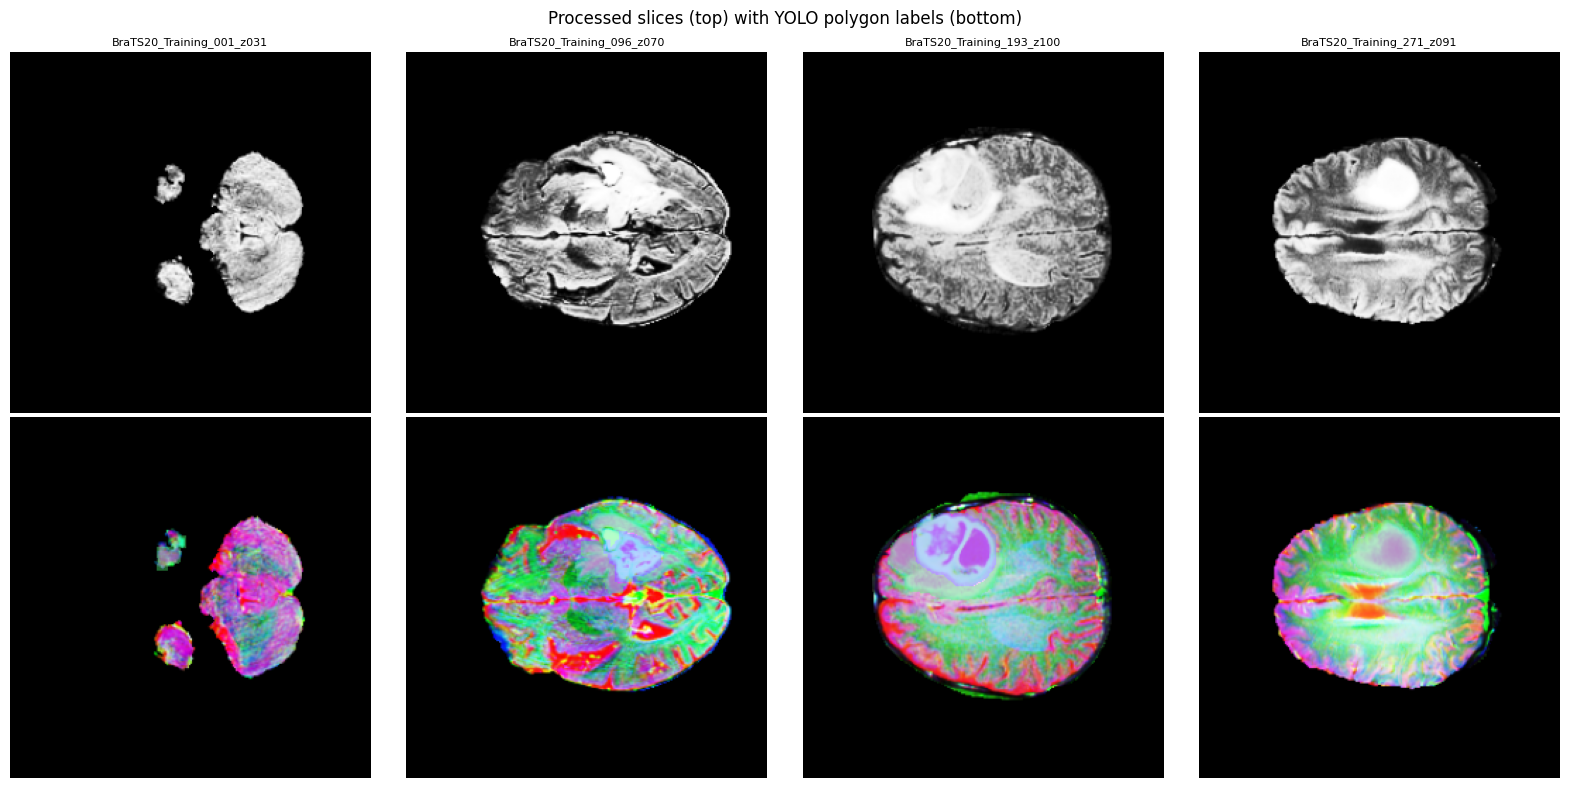

In [13]:
ROOT = Path("/content/brats-yolo-v2")
NAMES = ["necrotic_core", "edema", "enhancing_tumor"]
COLORS = [(80, 80, 255), (120, 255, 80), (255, 160, 80)]   # BGR

paths = sorted((ROOT / "images" / "train").glob("*.png"))
samples = paths[::max(1, len(paths) // 4)][:4]

fig, axes = plt.subplots(2, len(samples), figsize=(4 * len(samples), 8))

for col, image_path in enumerate(samples):
    image = cv2.imread(str(image_path))          # channels: flair, t1ce, t2
    height, width = image.shape[:2]

    overlay = image.copy()
    label_path = ROOT / "labels" / "train" / f"{image_path.stem}.txt"
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        parts = line.split()
        points = np.array(parts[1:], dtype=float).reshape(-1, 2)
        points[:, 0] *= width
        points[:, 1] *= height
        cv2.fillPoly(overlay, [points.astype(np.int32)], COLORS[int(parts[0])])
    blended = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)

    axes[0, col].imshow(image[:, :, 0], cmap="gray")
    axes[0, col].set_title(image_path.stem, fontsize=8)
    axes[1, col].imshow(blended[:, :, ::-1])

for ax in axes.ravel():
    ax.axis("off")

axes[0, 0].set_ylabel("FLAIR")
axes[1, 0].set_ylabel("labels")
plt.suptitle("Processed slices (top) with YOLO polygon labels (bottom)")
plt.tight_layout()
plt.show()

### The Model

In [14]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [15]:
from ultralytics import YOLO
model = YOLO("yolo11n-seg.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### Training

In [16]:
results = model.train(
    data=str(LOCAL_DATA / "data.yaml"),
    project=str(DRIVE_RUNS),
    name="adamw-b64",
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    epochs=100,
    imgsz=256,
    batch=64,
    workers=8,
    cache="ram",
    device=0,
    patience=30,
    fliplr=0.5,
    flipud=0.0,
    degrees=10.0,
    scale=0.3,
    mosaic=1.0,
    close_mosaic=10,
    seed=42,
)

Ultralytics 8.4.195 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/brats-yolo-v2/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=adamw-b64, nbs=64, nms=None, opset=None, optimize=F

In [17]:
# resume after disconnect
from ultralytics import YOLO
model = YOLO(f"{RUNS}/adamw-b64/weights/last.pt")
model.train(resume=True)

NameError: name 'RUNS' is not defined

In [18]:
# =========================================================================
metrics = model.val(data=str(ROOT / "data.yaml"), split="test", imgsz=512)

print(f"box  mAP50    {metrics.box.map50:.4f}")
print(f"box  mAP50-95 {metrics.box.map:.4f}")
print(f"mask mAP50    {metrics.seg.map50:.4f}")
print(f"mask mAP50-95 {metrics.seg.map:.4f}")

print("\nper class (mask):")
for idx, name in enumerate(NAMES):
  print(f"  {name:18s} mAP50={metrics.seg.ap50[idx]:.4f}")


Ultralytics 8.4.195 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,953 parameters, 0 gradients, 9.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 15.1±9.8 MB/s, size: 43.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/brats-yolo-v2/labels/test... 1120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1120/1120 1.1Kit/s 1.1s
val: New cache created: /content/brats-yolo-v2/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 70/70 4.6it/s 15.1s
                   all       1120       3193      0.658       0.47      0.508      0.256      0.646      0.476      0.481      0.196
         necrotic_core        435        513      0.471      0.323      0.311     0.0922   


0: 512x512 1 edema, 8.0ms
1: 512x512 1 edema, 8.0ms
2: 512x512 1 edema, 1 enhancing_tumor, 8.0ms
3: 512x512 1 edema, 1 enhancing_tumor, 8.0ms
Speed: 1.2ms preprocess, 8.0ms inference, 5.8ms postprocess per image at shape (1, 3, 512, 512)


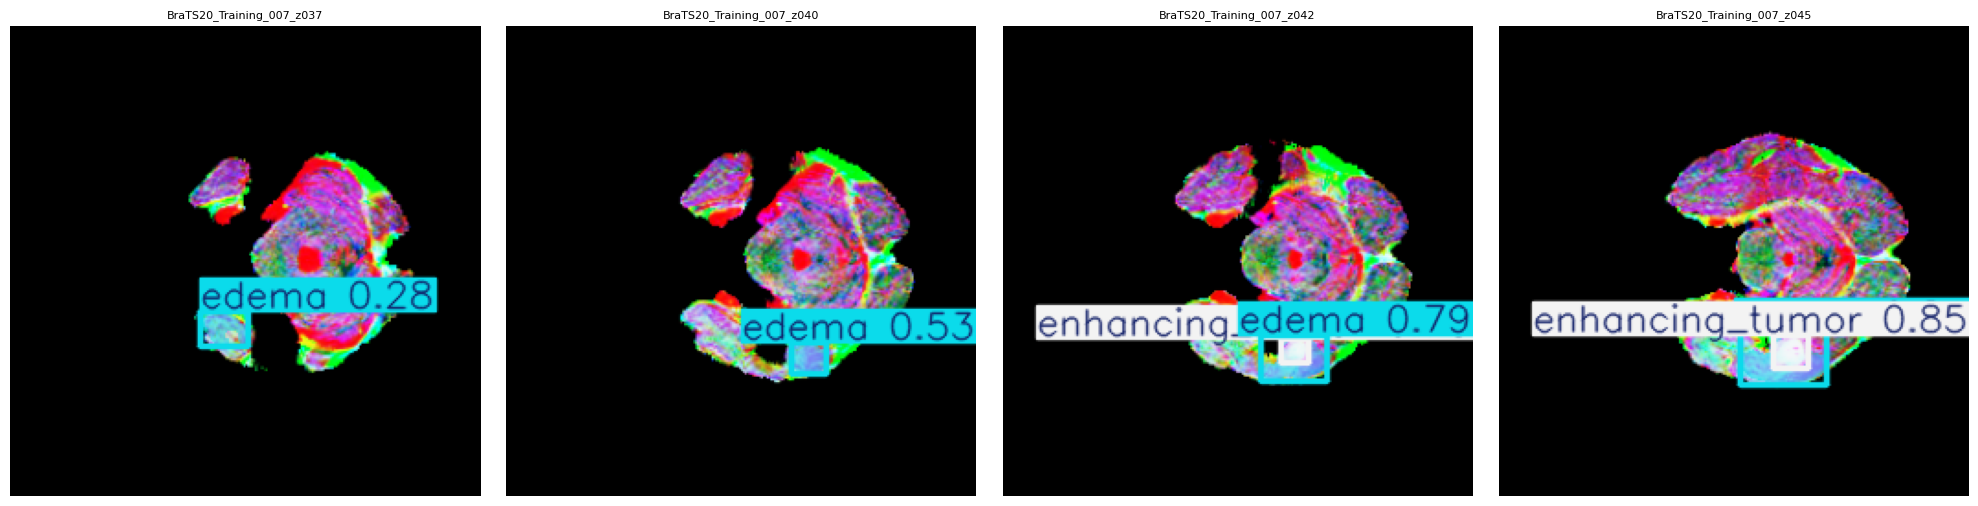

In [19]:
test_images = sorted((ROOT / "images" / "test").glob("*.png"))[:4]
predictions = model.predict(test_images, imgsz=512, conf=0.25)

fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 5))
for ax, prediction in zip(np.atleast_1d(axes), predictions):
  ax.imshow(prediction.plot()[:, :, ::-1])
  ax.set_title(Path(prediction.path).stem, fontsize=8)
  ax.axis("off")
plt.tight_layout()
plt.show()
